In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt

#from matplotlib import rcParams
#rcParams['font.family'] = 'serif'
#rcParams['text.usetex'] = 'true'
#rcParams['font.size'] = 16

from IPython.display import Markdown, display

In [2]:
def compute_metrics(labels, pred):
    
    fpr, tpr, thres = roc_curve(labels, pred)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    
    #optimal_index = np.argmax(tpr - fpr)
    #optimal_threshold = thres[optimal_index]

    binary_pred = np.where(pred < -0.5, 0, 1)    
    acc = balanced_accuracy_score(labels, binary_pred)
    
    return rocauc, eer, acc

In [8]:
def printmd(string):
    display(Markdown(string))

def print_results(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    all_scores = {}

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score']) 

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

        # Best scores
        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']
        best_bal_acc = max(scores, key=lambda x: x['bal_acc'])['bal_acc']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']
            bal_acc = s['bal_acc']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"
            bal_str = f"**{bal_acc*100:.2f}**" if bal_acc == best_bal_acc else f"{bal_acc*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str} \t Balanced Acc: {bal_str}\n\n"

        printmd(output)

    return all_scores


        
def print_results_NO_BACC(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    #dataset_list = glob('/nas/home/vnegroni/ispl_safe/results/*')
    all_scores = {}  # Store results in a dictionary

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score'])

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer
                })

                # Save to the main dictionary
                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer
                })

        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str}\n\n"

        printmd(output)

    return all_scores


def print_average_results_by_type(all_scores, known_datasets, subset='overall'):
    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]
        bals = [e['bal_acc'] for e in filtered]

        avg_auc = np.mean(aucs) if aucs else None
        avg_eer = np.mean(eers) if eers else None
        avg_bal = np.mean(bals) if bals else None

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer,
            'avg_bal': avg_bal
        })

    # Best values
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)
    best_bal = max((s['avg_bal'] for s in avg_scores if s['avg_bal'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer)
        bal_str = fmt(s['avg_bal'], best_bal)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str} \t Avg Balanced Acc: {bal_str}\n\n"

    printmd(output)

    
def print_average_results_by_type_NO_BACC(all_scores, known_datasets, subset='overall'):
    """
    subset: one of 'known', 'unknown', 'overall'
    """

    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        # Filter by subset
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:  # overall
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]

        if not aucs:
            avg_auc = None
            avg_eer = None
        else:
            avg_auc = np.mean(aucs)
            avg_eer = np.mean(eers)

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer
        })

    # Get best scores for formatting (highest AUC, lowest EER)
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer, is_best_fmt=True)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str}\n\n"

    printmd(output)


def plot_moe_expert_weights(
    results_root,
    npy_name,
    num_experts=4,
    max_datasets=4,
    figsize=(16, 3),
    expert_labels=None,
    hline=0.5
):
    """
    Plot average gating weights for MoE experts from multiple datasets.

    Args:
        results_root (str): Root folder containing dataset subfolders
        npy_name (str): Name of the .npy file to load (e.g. 'POC_MELE_CAT.npy')
        num_experts (int): Expected number of experts
        max_datasets (int): Max number of datasets/subplots
        figsize (tuple): Figure size
        expert_labels (list): Custom labels for experts
        hline (float): Horizontal reference line (e.g. 0.5)
    """

    dataset_list = glob(os.path.join(results_root, '*'))

    fig, axes = plt.subplots(1, max_datasets, figsize=figsize)
    axes = axes.flatten()

    if expert_labels is None:
        expert_labels = [f'E_{i}' for i in range(num_experts)]

    used_axes = 0

    for idx, dataset in enumerate(dataset_list[:max_datasets]):

        dataset_name = os.path.basename(dataset).upper()
        weights_path = os.path.join(dataset, npy_name)

        if not os.path.exists(weights_path):
            print(f'[WARN] Missing file: {weights_path}')
            continue

        expert_weights = np.load(weights_path).flatten()
        ax = axes[used_axes]

        if expert_weights.size != num_experts:
            print(
                f'[WARN] {dataset_name}: '
                f'expected {num_experts}, got {expert_weights.size}'
            )
            continue

        ax.bar(
            range(num_experts),
            expert_weights,
            tick_label=expert_labels
        )

        if hline is not None:
            ax.axhline(y=hline, color='red', linestyle='--', zorder=4)

        ax.set_title(f'DATASET: {dataset_name}')
        ax.set_xlabel('Experts')
        ax.set_ylabel('Average Gating Weight')
        ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

        used_axes += 1

    # Remove unused subplots
    for j in range(used_axes, max_datasets):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
    

# Performance Analysis

In [4]:
model_names = ["POC_MELE_CAT_FRZ", 
               "POC_MELE_CAT",
               "POC_MELE_TRANSF_FRZ",
               "POC_MELE_TRANSF"
              ]

dataset_list = [
    '/home/smg/v-viola/moe_antideepfake/results/POC/0_2000',
    '/home/smg/v-viola/moe_antideepfake/results/POC/2000_4000',
    '/home/smg/v-viola/moe_antideepfake/results/POC/4000_6000',
    '/home/smg/v-viola/moe_antideepfake/results/POC/6000_8000',
]

results = print_results_NO_BACC(model_names, dataset_list)

### 0_2000 DATASET

`POC_MELE_CAT`	 AUC: 99.99 	 EER: **0.02**

`POC_MELE_TRANSF_FRZ`	 AUC: **100.00** 	 EER: 0.16



### 2000_4000 DATASET

`POC_MELE_CAT`	 AUC: **99.55** 	 EER: **2.37**

`POC_MELE_TRANSF_FRZ`	 AUC: 98.09 	 EER: 3.71



### 4000_6000 DATASET

`POC_MELE_CAT`	 AUC: **96.35** 	 EER: **11.52**

`POC_MELE_TRANSF_FRZ`	 AUC: 88.67 	 EER: 16.63



### 6000_8000 DATASET

`POC_MELE_CAT`	 AUC: **93.42** 	 EER: **17.30**

`POC_MELE_TRANSF_FRZ`	 AUC: 80.80 	 EER: 26.72



# Gating Weights Analysis

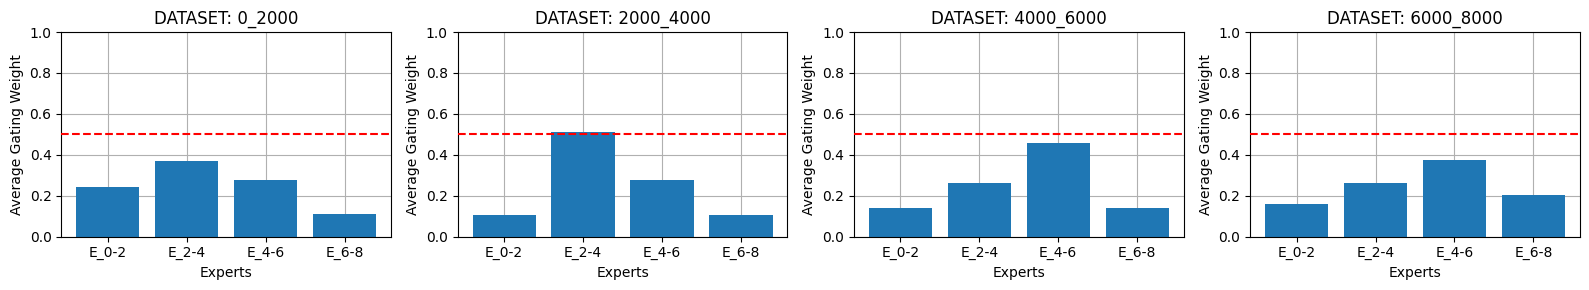

In [7]:
plot_moe_expert_weights(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC',
    npy_name='POC_MELE_CAT.npy',
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

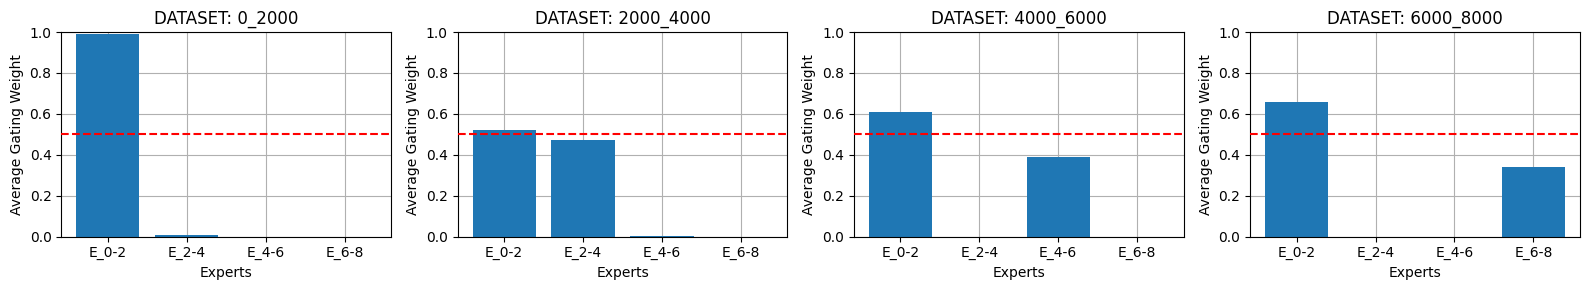

In [9]:
plot_moe_expert_weights(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC',
    npy_name='POC_MELE_TRANSF_FRZ.npy',
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)